In [41]:
import torch
import torch.nn as nn
import torch.optim as optim

import snntorch as snn
from snntorch import spikegen
from snntorch import surrogate, functional as SF

import pandas as pd
import numpy as np

from torch.utils.data import DataLoader, TensorDataset

from scipy.stats import beta as beta_dist
import scipy.io as sio

import pickle
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold

In [42]:
num_steps = 164

THRESHOLD_HIDDEN = 0.3
THRESHOLD_OUTPUT = 0.1
SCALING_FACTOR = 0.1
SPIKE_GAIN_INIT = 1.3
LAMBDA_BP = 1.0     # start here, tune up if predictions still collapse to mean

SMOOTHING = True

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

num_folds = 5

lr = 5e-4
eps = 1e-8

kernel_tau = 20.0
kernel_decay = torch.exp(torch.tensor(-1.0 / kernel_tau))

# TODO:
# - The ABP signal is not following the original signal.
#   Something is wrong with the loss function.
# - If there are two spikes in the original signal,
#   only the first one is detected.
# These are currently hypotheses and need investigation.

LAMBDA_LM = 0.5

SP_MEAN_ALL = 121.0
DP_MEAN_ALL = 67.2

CONN_PROB = 0.5

## Data Loading


In [43]:
def load_data(fold_num):
    return pd.read_csv(f"bcg_dataset/feat_fold_{fold_num}.csv")

def load_abp(fold_num):
    mat = sio.loadmat(f"bcg_dataset/signal_mabp_fold_{fold_num}.mat")
    return mat["abp_signal"]


def load_limits(fold_num):
    mat = sio.loadmat(f"bcg_dataset/signal_mabp_fold_{fold_num}.mat")
    return mat["class_limits"] - 1


abp_all = np.concatenate([load_abp(i) for i in range(num_folds)])

# Computed from all training data and stored as a fixed constant.
GLOBAL_MEAN_T0 = (abp_all[:, 0] / 100.0).mean()

print(f"Global mean first ABP timestep (normalised): {GLOBAL_MEAN_T0:.4f}")
print(f"= {GLOBAL_MEAN_T0 * 100:.2f} mmHg")

Global mean first ABP timestep (normalised): 0.6725
= 67.25 mmHg


## Plotting

In [44]:
def plot_predictions(all_true, all_predictions, label, fold, samplingRange):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Scatter plot: predicted vs. true values
    axes[0].scatter(all_true, all_predictions, alpha=0.4, s=10)
    axes[0].plot(
        [all_true.min(), all_true.max()],
        [all_true.min(), all_true.max()],
        "r--",
        label="Perfect prediction",
    )
    axes[0].set_xlabel(f"True {label}")
    axes[0].set_ylabel(f"Predicted {label}")
    axes[0].set_title(f"Fold {fold + 1} - Predicted vs True {label}")
    axes[0].legend()

    # Time series comparison
    axes[1].plot(
        all_true[:samplingRange],
        label=f"True {label}",
        alpha=0.8,
    )
    axes[1].plot(
        all_predictions[:samplingRange],
        label=f"Predicted {label}",
        alpha=0.8,
    )
    axes[1].set_xlabel("Sample")
    axes[1].set_ylabel(f"{label} (mmHg)")
    axes[1].set_title(f"Fold {fold + 1} - First {samplingRange} Samples")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

def plot_signal(signal, spk_rec, abp_target, lim_batch, sample_idx=0):
    """
    Plot the kernel output signal together with the target ABP.
    Shows the first-cycle cutoff from class_limits.
    """

    sig = signal[:, sample_idx, 0].detach().cpu().numpy()
    spk = spk_rec[:, sample_idx, 0].detach().cpu().numpy()
    target = (abp_target[sample_idx] / 100.0).detach().cpu().numpy()
    cycle_end = int(lim_batch[sample_idx, -1].item())

    spike_times = np.where(spk > 0)[0]

    plt.close("all")
    plt.figure(figsize=(10, 4))

    for t in spike_times:
        plt.axvline(x=t, color="black", alpha=0.4, linewidth=0.8)

    plt.plot(sig, color="steelblue", label="Kernel output signal", zorder=2)
    plt.plot(
        target,
        color="red",
        linestyle="--",
        label="True ABP (visual reference only)",
    )

    plt.axvline(
        x=cycle_end, color="green", linestyle="-", linewidth=2,
        label=f"First cycle end (t={cycle_end})", zorder=3,
    )

    plt.xlabel("Timestep")
    plt.ylabel("BP (normalised)")
    plt.title(f"Sample {sample_idx} - Kernel output vs ABP target")
    plt.legend()

    plt.show()


'''
def plot_signal(signal, spk_rec, abp_target, sample_idx=0):
    """
    Plot the kernel output signal together with the target ABP.

    Note:
        `abp_target` is used for visual reference only.
        Predictions come from `extract_BP_limits`; the ABP signal is
        not used during prediction.
    """

    sig = signal[:, sample_idx, 0].detach().cpu().numpy()
    spk = spk_rec[:, sample_idx, 0].detach().cpu().numpy()
    target = (abp_target[sample_idx] / 100.0).detach().cpu().numpy()

    spike_times = np.where(spk > 0)[0]

    plt.close("all")
    plt.figure(figsize=(10, 4))

    for t in spike_times:
        plt.axvline(x=t, color="black", alpha=0.4, linewidth=0.8)

    plt.plot(sig, color="steelblue", label="Kernel output signal", zorder=2)
    plt.plot(
        target,
        color="red",
        linestyle="--",
        label="True ABP (visual reference only)",
    )

    plt.xlabel("Timestep")
    plt.ylabel("BP (normalised)")
    plt.title(f"Sample {sample_idx} - Kernel output vs ABP target")
    plt.legend()

    plt.show()
'''

'\ndef plot_signal(signal, spk_rec, abp_target, sample_idx=0):\n    """\n    Plot the kernel output signal together with the target ABP.\n\n    Note:\n        `abp_target` is used for visual reference only.\n        Predictions come from `extract_BP_limits`; the ABP signal is\n        not used during prediction.\n    """\n\n    sig = signal[:, sample_idx, 0].detach().cpu().numpy()\n    spk = spk_rec[:, sample_idx, 0].detach().cpu().numpy()\n    target = (abp_target[sample_idx] / 100.0).detach().cpu().numpy()\n\n    spike_times = np.where(spk > 0)[0]\n\n    plt.close("all")\n    plt.figure(figsize=(10, 4))\n\n    for t in spike_times:\n        plt.axvline(x=t, color="black", alpha=0.4, linewidth=0.8)\n\n    plt.plot(sig, color="steelblue", label="Kernel output signal", zorder=2)\n    plt.plot(\n        target,\n        color="red",\n        linestyle="--",\n        label="True ABP (visual reference only)",\n    )\n\n    plt.xlabel("Timestep")\n    plt.ylabel("BP (normalised)")\n    plt.

## Core Functions

In [45]:
'''
def extract_BP_limits(sig, limits_batch=None):
    """
    Estimate systolic and diastolic blood pressure from the reconstructed signal.
    """

    s = sig[:, :, 0]  # Shape: [T, B]

    pred_sbp = s.max(dim=0).values * 100.0

    # Latest systolic peak across the batch
    peak_idx = s.argmax(dim=0).max().item()

    # Diastolic value = minimum after the peak
    pred_dbp = s[peak_idx:].min(dim=0).values * 100.0

    return pred_sbp, pred_dbp
'''

def extract_BP_limits(sig, limits_batch):
    """
    Extract SBP and DBP from the reconstructed signal,
    using class_limits to restrict extraction to the first
    cardiac cycle only (ignoring repeated cycles in the 
    164-step window).
    """
    s = sig[:, :, 0]  # Shape: [T, B]
    B = s.shape[1]

    # Last column of class_limits = end of first cycle
    cycle_end = limits_batch[:, -1]

    pred_sbp = torch.stack([
        s[:cycle_end[b], b].max() for b in range(B)
    ]) * 100.0

    # Systolic peak position within first cycle
    peak_idx = torch.stack([
        s[:cycle_end[b], b].argmax() for b in range(B)
    ])

    # DBP = minimum after the systolic peak, within first cycle
    pred_dbp = torch.stack([
        s[peak_idx[b]:cycle_end[b], b].min() for b in range(B)
    ]) * 100.0

    return pred_sbp, pred_dbp


def apply_exponential_kernel(spk_rec, decay, spike_gain, init_val):
    """
    spk_rec:    [T, B, N_output]
    spike_gain: [N_output] learnable
    init_val:   [B, 1] predicted by the network from features
    """
    weighted = (spk_rec * spike_gain.view(1, 1, -1)).mean(dim=-1, keepdim=True)

    signal = (init_val / SCALING_FACTOR).clone()

    out = []
    for t in range(weighted.shape[0]):
        signal = decay * signal + weighted[t]
        out.append(signal)

    return torch.stack(out, dim=0)


def smooth(sig, window=10):
    """
    Apply a moving-average smoothing filter.
    """

    kernel = torch.ones(1, 1, window, device=sig.device) / window

    x = sig.permute(1, 2, 0)
    x = torch.nn.functional.pad(x, (window - 1, 0))
    x = torch.nn.functional.conv1d(x, kernel, groups=1)

    return x.permute(2, 0, 1)

def combined_loss(sig, target, lim, sbp_true, dbp_true, bp_mean):
    """
    Three terms:
      1. waveform reconstruction over the first cycle only
      2. landmark error at systolic and diastolic points
      3. direct error on the extracted SBP/DBP values
    """
    B = sig.shape[1]
    device_ = sig.device

    weight = 1.0 + torch.abs(sbp_true - bp_mean) / bp_mean

    # --- 1. waveform loss, masked to first cycle -------------------
    T = sig.shape[0]
    idx = torch.arange(T, device=device_).view(T, 1)
    cycle_end = lim[:, -1].view(1, B).to(device_)
    mask = (idx < cycle_end).float().unsqueeze(-1)     # [T, B, 1]

    abs_err = torch.abs(sig - target) * mask
    waveform_mae = abs_err.sum(dim=0)[:, 0] / mask.sum(dim=0)[:, 0].clamp(min=1)
    waveform_loss = (waveform_mae * weight).mean()

    # --- 2. landmark loss ------------------------------------------
    sys_idx = lim[:, 0]
    dia_idx = lim[:, 2]
    lm_errors = torch.stack([
        torch.abs(sig[sys_idx[b], b, 0] - target[sys_idx[b], b, 0])
        + torch.abs(sig[dia_idx[b], b, 0] - target[dia_idx[b], b, 0])
        for b in range(B)
    ])
    landmark_loss = (lm_errors * weight).mean()

    # --- 3. direct BP loss -----------------------------------------
    pred_sbp, pred_dbp = extract_BP_limits(sig, lim)
    bp_loss = (
        torch.abs(pred_sbp - sbp_true) + torch.abs(pred_dbp - dbp_true)
    ).mean() / 100.0                      # scale to match normalised units

    return (
        waveform_loss
        + LAMBDA_LM * landmark_loss
        + LAMBDA_BP * bp_loss
    )

## Network

In [46]:
def make_spike_time_encoding(num_steps, num_timers, device):
    anchor_times = [17, 51, 115, 130]
    num_remaining = num_timers - len(anchor_times)
    uniform_times = torch.linspace(0, num_steps - 1, num_remaining).long().tolist()
    all_times = sorted(set(anchor_times + uniform_times))[:num_timers]
    enc = torch.zeros(num_steps, num_timers, device=device)
    for i, t in enumerate(all_times):
        enc[t, i] = 1.0
    return enc

class Net(nn.Module):
    def __init__(self, num_inputs, num_hidden, num_outputs, beta_val,
                 num_steps=164, num_timers=10):
        super().__init__()
        self.num_steps = num_steps
        self.num_timers = num_timers
        self.init_readout = nn.Linear(num_inputs, 1)
        self.refractory_steps = REFRACTORY_STEPS

        beta1 = torch.clamp(torch.randn(num_hidden) * 0.05 + beta_val, 0.5, 0.99)
        beta2 = torch.clamp(torch.randn(num_outputs) * 0.05 + beta_val, 0.5, 0.99)

        thresh1 = torch.clamp(torch.randn(num_hidden) * 0.05 + THRESHOLD_HIDDEN, 0.1, 1.0)
        thresh2 = torch.clamp(torch.randn(num_outputs) * 0.05 + THRESHOLD_OUTPUT, 0.1, 1.0)

        self.fc1 = nn.Linear(num_inputs + num_timers, num_hidden)
        self.lif1 = snn.Leaky(beta=beta1, threshold=thresh1,
                              learn_beta=True, learn_threshold=True)

        self.fc2 = nn.Linear(num_hidden, num_outputs)
        self.lif2 = snn.Leaky(beta=beta2, threshold=thresh2,
                              learn_beta=True, learn_threshold=True)

        self.spike_gain = nn.Parameter(torch.ones(num_outputs) * SPIKE_GAIN_INIT)

        self.register_buffer("mask1", (torch.rand_like(self.fc1.weight) < CONN_PROB).float())
        self.register_buffer("mask2", (torch.rand_like(self.fc2.weight) < CONN_PROB).float())

    def forward(self, xfeatures):
        mem1 = self.lif1.reset_mem()
        mem2 = self.lif2.reset_mem()

        # Predicted kernel starting value, normalised BP units
        init_val = torch.sigmoid(self.init_readout(xfeatures)) * 0.6 + 0.5
        # maps to roughly [0.5, 1.1] normalised = 50-110 mmHg

        spk_rec = []

        input_spikes = spikegen.rate(xfeatures, num_steps=self.num_steps).to(device)
        time_enc = make_spike_time_encoding(self.num_steps, self.num_timers, device=xfeatures.device)

        refrac1 = torch.zeros(xfeatures.shape[0], self.fc1.out_features, device=xfeatures.device)
        refrac2 = torch.zeros(xfeatures.shape[0], self.fc2.out_features, device=xfeatures.device)

        for t in range(self.num_steps):
            t_spk = time_enc[t].unsqueeze(0).expand(input_spikes[t].shape[0], -1)
            inp = torch.cat([input_spikes[t], t_spk], dim=-1)

            cur1 = nn.functional.linear(inp, self.fc1.weight * self.mask1, self.fc1.bias)
            cur1 = cur1 * (refrac1 <= 0).float()
            spk1, mem1 = self.lif1(cur1, mem1)
            refrac1 = torch.where(spk1 > 0,
                                  torch.full_like(refrac1, self.refractory_steps),
                                  (refrac1 - 1).clamp(min=0))

            cur2 = nn.functional.linear(spk1, self.fc2.weight * self.mask2, self.fc2.bias)
            cur2 = cur2 * (refrac2 <= 0).float()
            spk2, mem2 = self.lif2(cur2, mem2)
            refrac2 = torch.where(spk2 > 0,
                                  torch.full_like(refrac2, self.refractory_steps),
                                  (refrac2 - 1).clamp(min=0))

            spk_rec.append(spk2)

        return torch.stack(spk_rec, dim=0), init_val  # [T, B, N_output], initial starting value

## Load Features

In [47]:
with open("FeatureRanking_Results/rf_results.pkl", "rb") as f:
    ranking = pickle.load(f)

top_features_SBP = [f for f, _ in ranking["sbp_ranking_pearson"][:10]]
top_features_DBP = [f for f, _ in ranking["dbp_ranking_pearson"][:10]]

print("SBP features:", top_features_SBP)
print("DBP features:", top_features_DBP)

top_features_ALL = list(dict.fromkeys(top_features_SBP + top_features_DBP))

print("combined features:", len(top_features_ALL))

SBP features: ['AUCsys_norm', 'TdiaToEnd', 'T_peak_e_norm', 'ppg_histogram_down_2', 'T_peak_a', 'SteepDiaRise', 'TNegSteepest_norm', 'ppg4_max_0', 'TSystoDiaRise', 'ppg3_histogram_down_8']
DBP features: ['TdiaToEnd', 'dsdc_8', 'ppg_histogram_down_4', 'S4', 'vpg_histogram_down_0', 'T_peak_e', 'T_peak_a', 'ppg4_histogram_down_3', 'SteepDiaRise', 'ppg3_histogram_down_8']
combined features: 16


## Training Loop


Fold 1/5
  Epoch  1 | Loss: 1.0616
  Epoch  2 | Loss: 0.7687
  Epoch  3 | Loss: 0.6763
  Epoch  4 | Loss: 0.5870
  Epoch  5 | Loss: 0.4826
  Epoch  6 | Loss: 0.4205
  Epoch  7 | Loss: 0.3934
  Epoch  8 | Loss: 0.3822
  Epoch  9 | Loss: 0.3807
  Epoch 10 | Loss: 0.3769
  Epoch 11 | Loss: 0.3746
  Epoch 12 | Loss: 0.3723
  Epoch 13 | Loss: 0.3697
  Epoch 14 | Loss: 0.3699
  Epoch 15 | Loss: 0.3686
  Epoch 16 | Loss: 0.3631
  Epoch 17 | Loss: 0.3619
  Epoch 18 | Loss: 0.3588
  Epoch 19 | Loss: 0.3592
  Epoch 20 | Loss: 0.3539
  Epoch 21 | Loss: 0.3561
  Epoch 22 | Loss: 0.3528
  Epoch 23 | Loss: 0.3539
  Epoch 24 | Loss: 0.3497
  Epoch 25 | Loss: 0.3490
  Epoch 26 | Loss: 0.3510
  Epoch 27 | Loss: 0.3476
  Epoch 28 | Loss: 0.3472
  Epoch 29 | Loss: 0.3486
  Epoch 30 | Loss: 0.3413
    Saved checkpoint: checkpoint_fold_1.pt


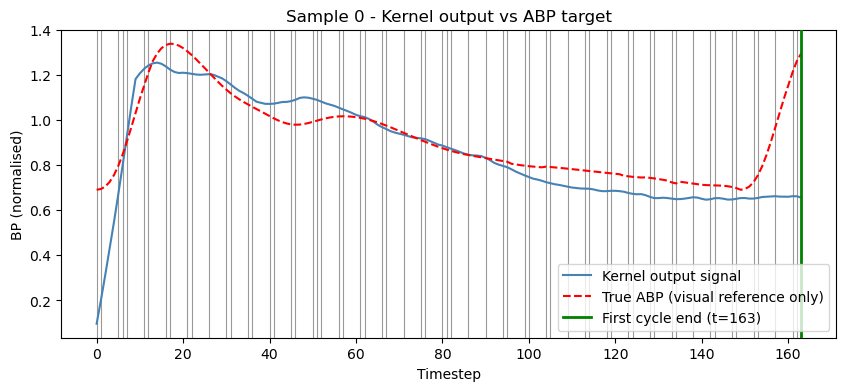

  → Fold MAE  SBP: 16.8887  DBP: 8.8512


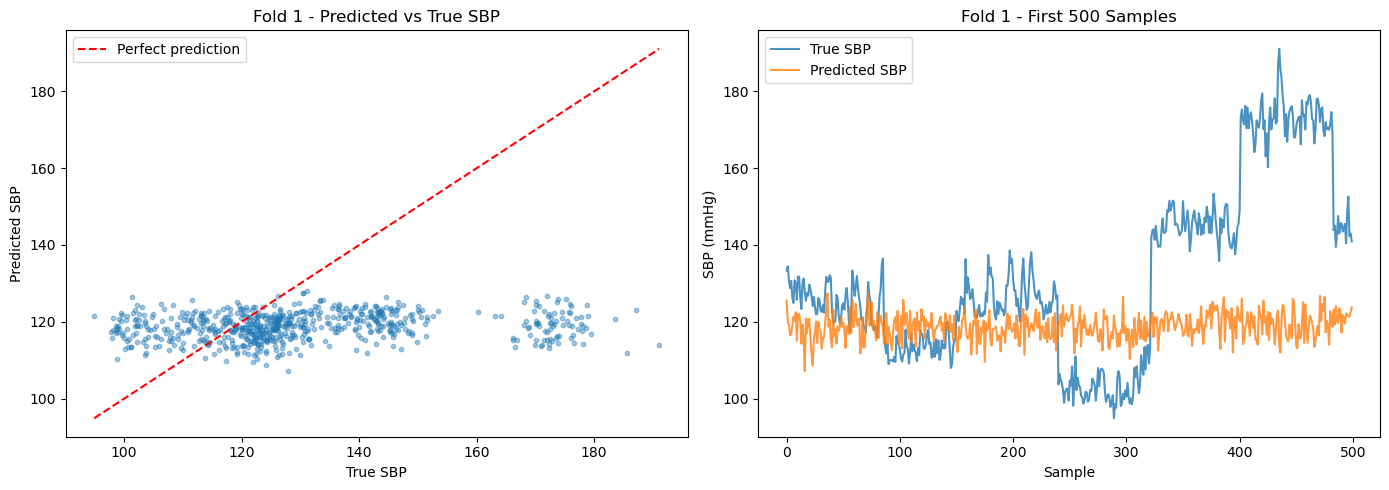

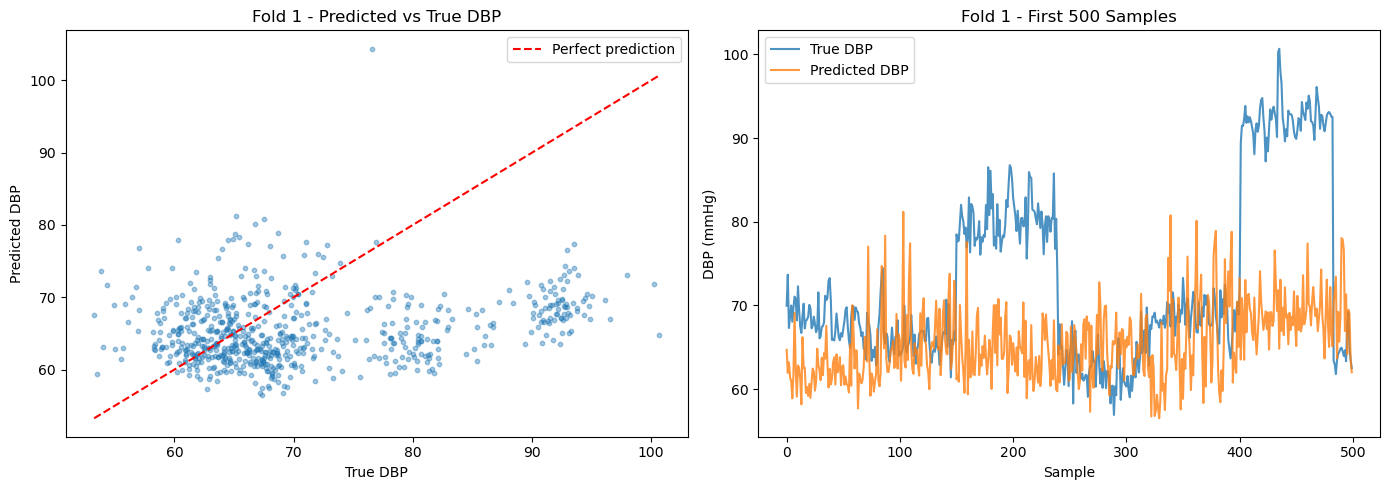


Final CV MAE's:
  SBP: 16.8887 ± 0.0000
  DBP: 8.8512 ± 0.0000

Fold 2/5
  Epoch  1 | Loss: 1.2291
  Epoch  2 | Loss: 0.7912
  Epoch  3 | Loss: 0.6846
  Epoch  4 | Loss: 0.5484
  Epoch  5 | Loss: 0.4782
  Epoch  6 | Loss: 0.4517
  Epoch  7 | Loss: 0.4353
  Epoch  8 | Loss: 0.4292
  Epoch  9 | Loss: 0.4258
  Epoch 10 | Loss: 0.4249
  Epoch 11 | Loss: 0.4174
  Epoch 12 | Loss: 0.4202
  Epoch 13 | Loss: 0.4180
  Epoch 14 | Loss: 0.4174
  Epoch 15 | Loss: 0.4130
  Epoch 16 | Loss: 0.4161
  Epoch 17 | Loss: 0.4129
  Epoch 18 | Loss: 0.4129
  Epoch 19 | Loss: 0.4073
  Epoch 20 | Loss: 0.4112
  Epoch 21 | Loss: 0.4078
  Epoch 22 | Loss: 0.4088
  Epoch 23 | Loss: 0.4047
  Epoch 24 | Loss: 0.4021
  Epoch 25 | Loss: 0.4050
  Epoch 26 | Loss: 0.4051
  Epoch 27 | Loss: 0.3996
  Epoch 28 | Loss: 0.4006
  Epoch 29 | Loss: 0.3998
  Epoch 30 | Loss: 0.3998
    Saved checkpoint: checkpoint_fold_2.pt


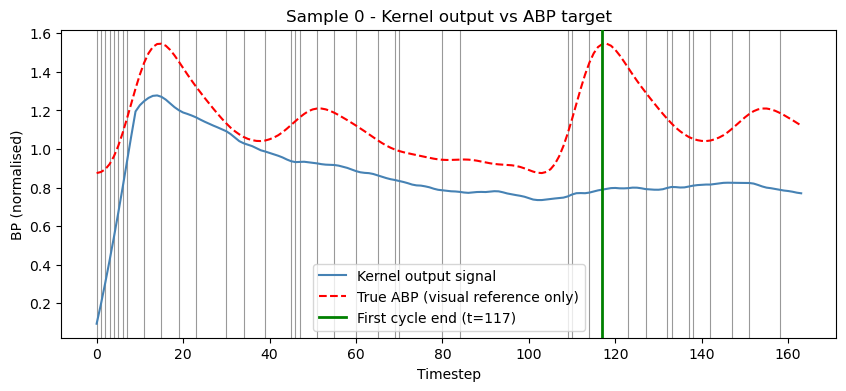

  → Fold MAE  SBP: 11.2034  DBP: 8.4120


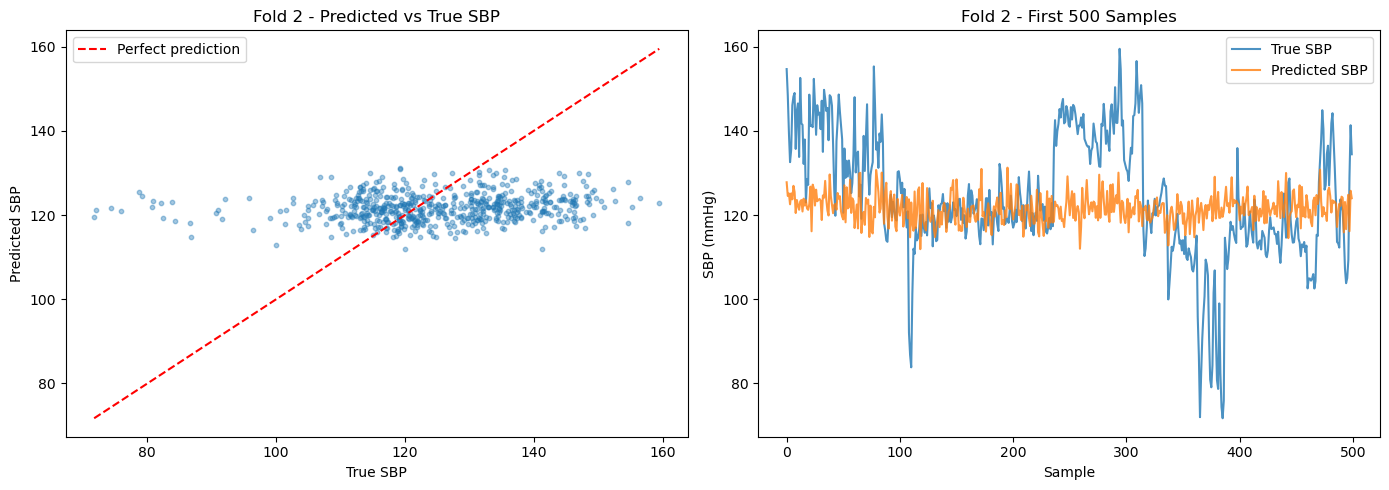

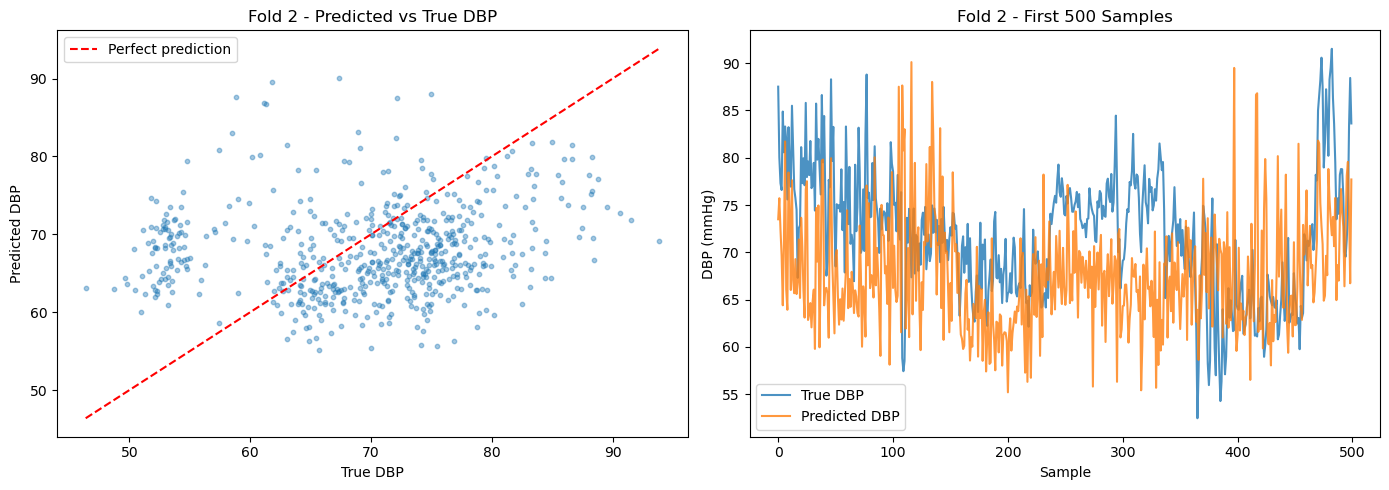


Final CV MAE's:
  SBP: 14.1722 ± 2.8427
  DBP: 8.6413 ± 0.2196

Fold 3/5
  Epoch  1 | Loss: 1.3282
  Epoch  2 | Loss: 0.8348
  Epoch  3 | Loss: 0.7570
  Epoch  4 | Loss: 0.6832
  Epoch  5 | Loss: 0.5834
  Epoch  6 | Loss: 0.5073
  Epoch  7 | Loss: 0.4820
  Epoch  8 | Loss: 0.4640
  Epoch  9 | Loss: 0.4639
  Epoch 10 | Loss: 0.4615
  Epoch 11 | Loss: 0.4570
  Epoch 12 | Loss: 0.4489
  Epoch 13 | Loss: 0.4514
  Epoch 14 | Loss: 0.4478
  Epoch 15 | Loss: 0.4394
  Epoch 16 | Loss: 0.4380
  Epoch 17 | Loss: 0.4351
  Epoch 18 | Loss: 0.4355
  Epoch 19 | Loss: 0.4294
  Epoch 20 | Loss: 0.4291
  Epoch 21 | Loss: 0.4268
  Epoch 22 | Loss: 0.4235
  Epoch 23 | Loss: 0.4230
  Epoch 24 | Loss: 0.4207
  Epoch 25 | Loss: 0.4235
  Epoch 26 | Loss: 0.4247
  Epoch 27 | Loss: 0.4183
  Epoch 28 | Loss: 0.4173
  Epoch 29 | Loss: 0.4186
  Epoch 30 | Loss: 0.4145
    Saved checkpoint: checkpoint_fold_3.pt


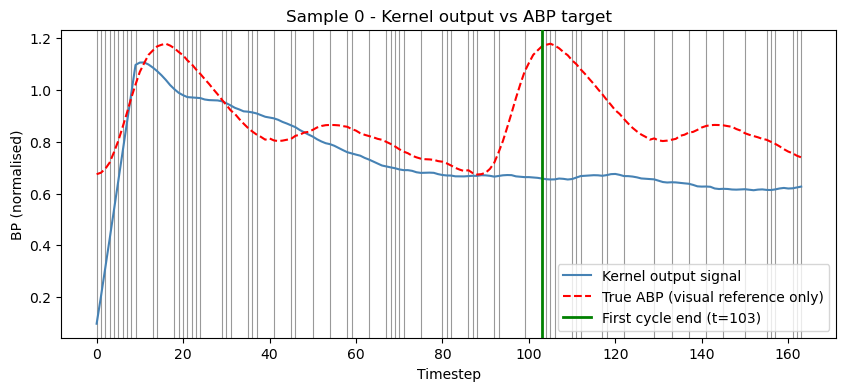

  → Fold MAE  SBP: 8.2648  DBP: 6.1797


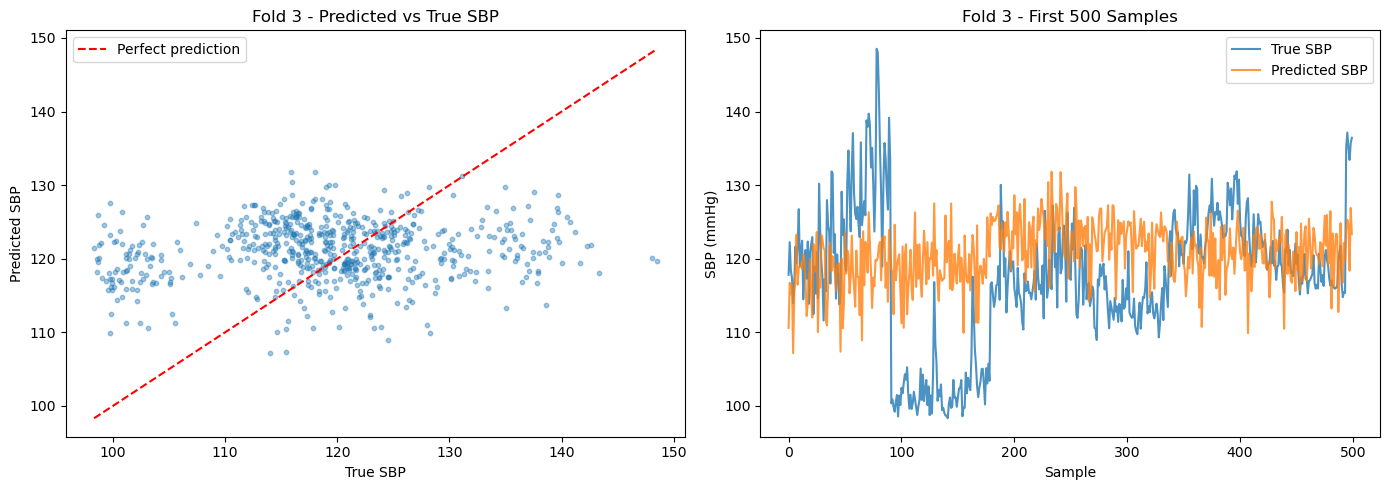

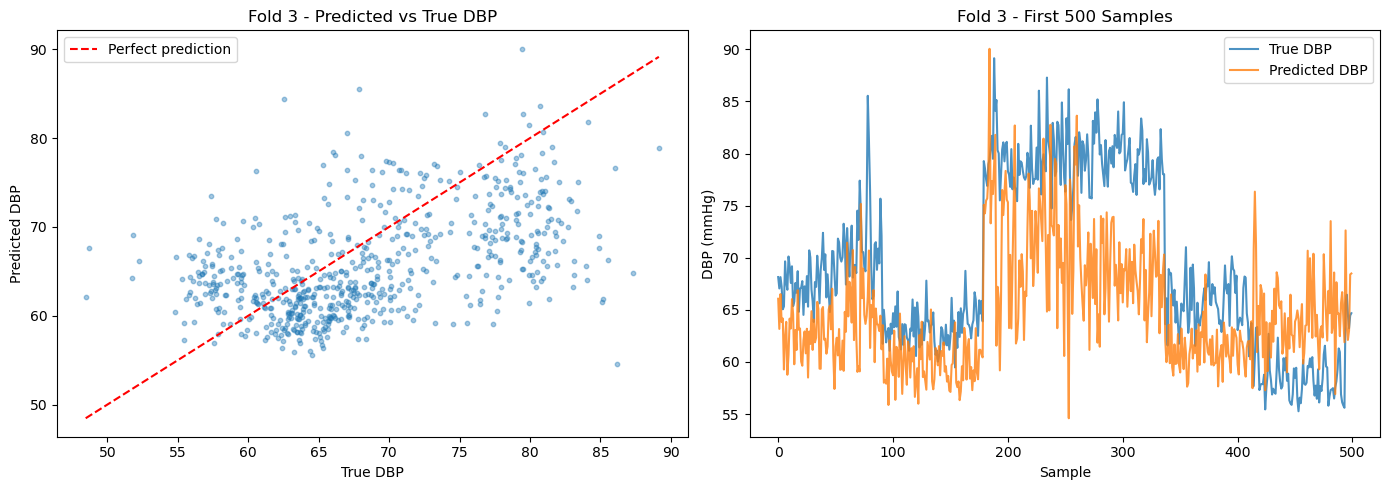


Final CV MAE's:
  SBP: 12.1837 ± 3.5797
  DBP: 7.8127 ± 1.1697

Fold 4/5
  Epoch  1 | Loss: 1.4778
  Epoch  2 | Loss: 0.8299
  Epoch  3 | Loss: 0.7398
  Epoch  4 | Loss: 0.6485
  Epoch  5 | Loss: 0.5742
  Epoch  6 | Loss: 0.5108
  Epoch  7 | Loss: 0.4686
  Epoch  8 | Loss: 0.4503
  Epoch  9 | Loss: 0.4429
  Epoch 10 | Loss: 0.4354
  Epoch 11 | Loss: 0.4330
  Epoch 12 | Loss: 0.4293
  Epoch 13 | Loss: 0.4288
  Epoch 14 | Loss: 0.4226
  Epoch 15 | Loss: 0.4205
  Epoch 16 | Loss: 0.4220
  Epoch 17 | Loss: 0.4164
  Epoch 18 | Loss: 0.4128
  Epoch 19 | Loss: 0.4099
  Epoch 20 | Loss: 0.4074
  Epoch 21 | Loss: 0.4078
  Epoch 22 | Loss: 0.4066
  Epoch 23 | Loss: 0.4070
  Epoch 24 | Loss: 0.4019
  Epoch 25 | Loss: 0.4016
  Epoch 26 | Loss: 0.3985
  Epoch 27 | Loss: 0.3998
  Epoch 28 | Loss: 0.3947
  Epoch 29 | Loss: 0.3985
  Epoch 30 | Loss: 0.3962
    Saved checkpoint: checkpoint_fold_4.pt


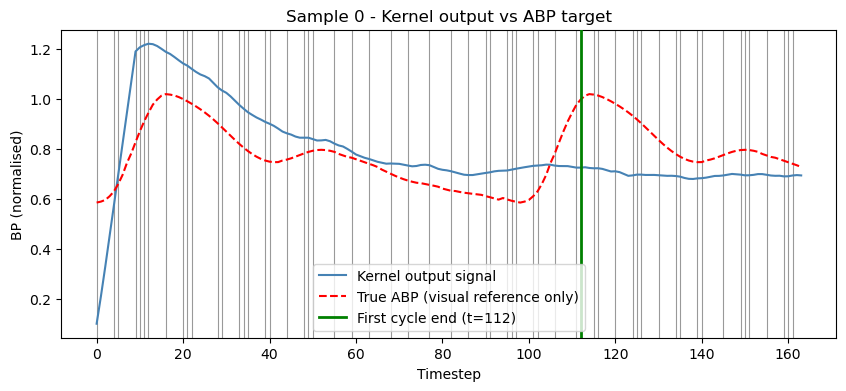

  → Fold MAE  SBP: 11.6435  DBP: 7.5088


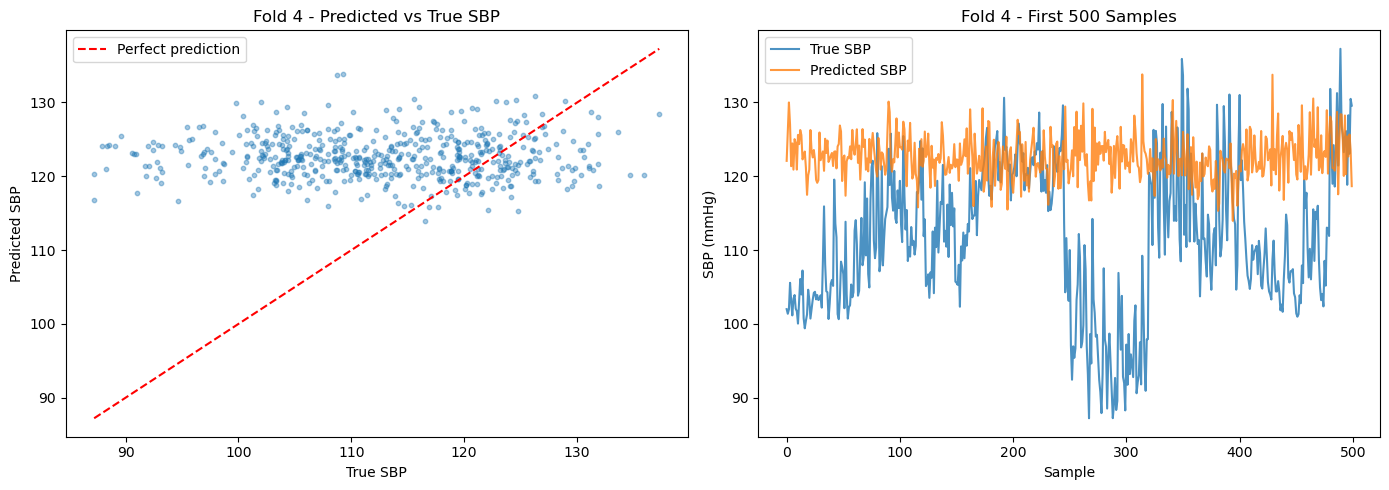

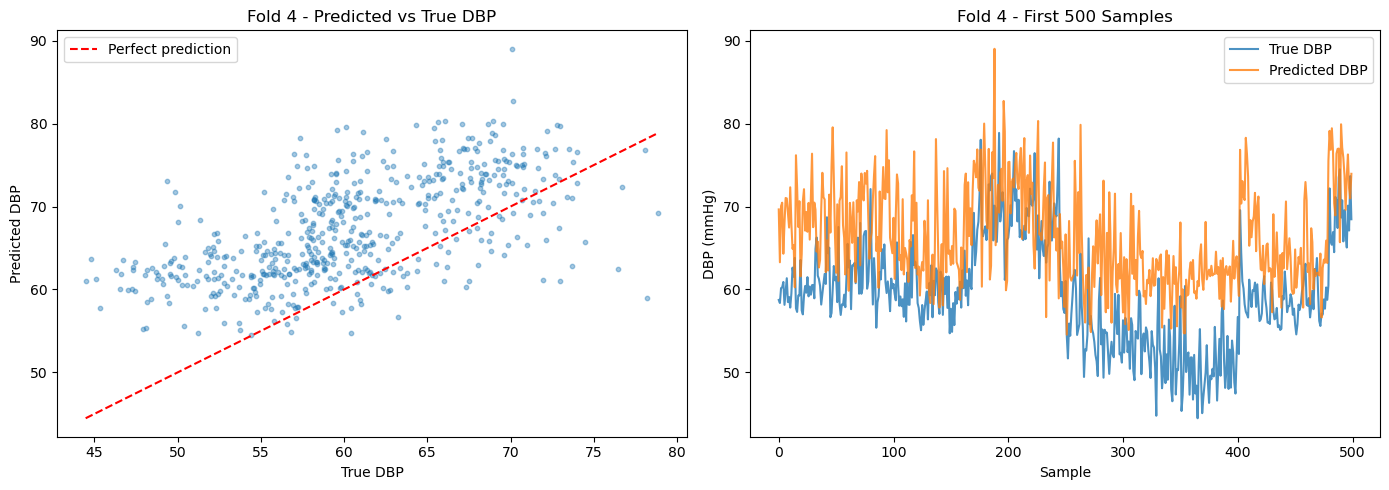


Final CV MAE's:
  SBP: 12.0631 ± 3.1070
  DBP: 7.7449 ± 1.0216

Fold 5/5
  Epoch  1 | Loss: 1.2635
  Epoch  2 | Loss: 0.9616
  Epoch  3 | Loss: 0.8703
  Epoch  4 | Loss: 0.7262
  Epoch  5 | Loss: 0.6101
  Epoch  6 | Loss: 0.5241
  Epoch  7 | Loss: 0.4685
  Epoch  8 | Loss: 0.4520
  Epoch  9 | Loss: 0.4477
  Epoch 10 | Loss: 0.4462
  Epoch 11 | Loss: 0.4413
  Epoch 12 | Loss: 0.4357
  Epoch 13 | Loss: 0.4372
  Epoch 14 | Loss: 0.4337
  Epoch 15 | Loss: 0.4285
  Epoch 16 | Loss: 0.4265
  Epoch 17 | Loss: 0.4245
  Epoch 18 | Loss: 0.4206
  Epoch 19 | Loss: 0.4237
  Epoch 20 | Loss: 0.4192
  Epoch 21 | Loss: 0.4193
  Epoch 22 | Loss: 0.4181
  Epoch 23 | Loss: 0.4141
  Epoch 24 | Loss: 0.4123
  Epoch 25 | Loss: 0.4157
  Epoch 26 | Loss: 0.4121
  Epoch 27 | Loss: 0.4062
  Epoch 28 | Loss: 0.4111
  Epoch 29 | Loss: 0.4075
  Epoch 30 | Loss: 0.4020
    Saved checkpoint: checkpoint_fold_5.pt


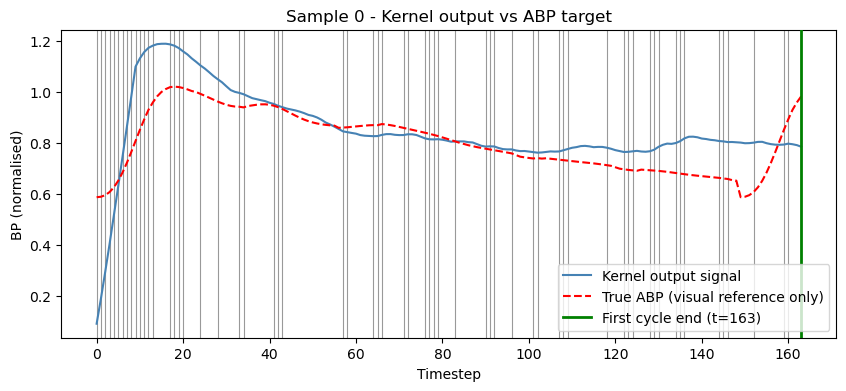

  → Fold MAE  SBP: 10.5545  DBP: 6.0709


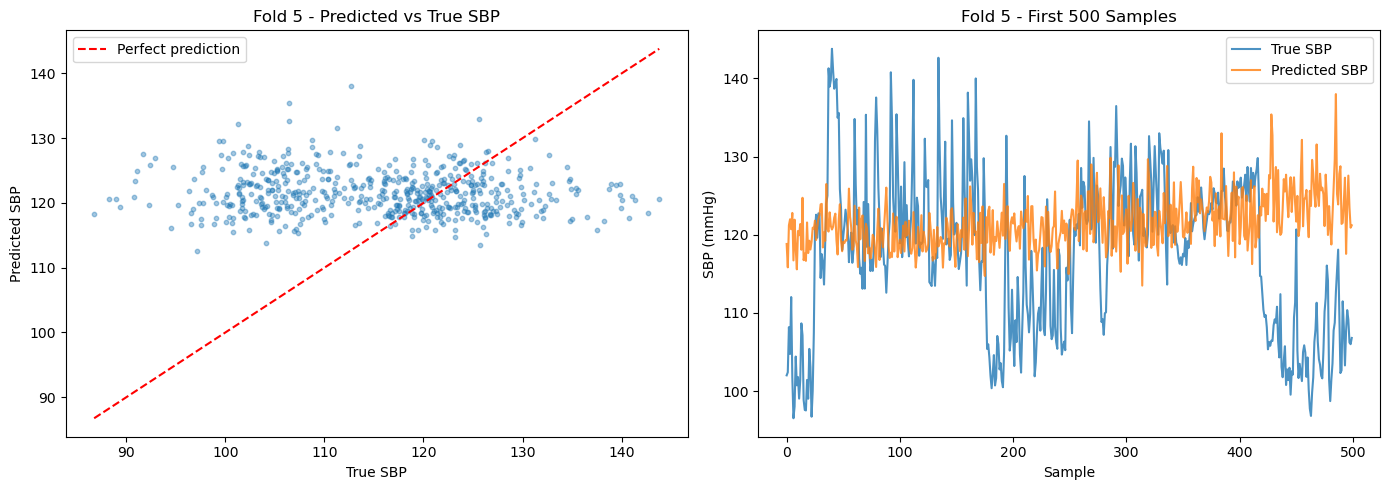

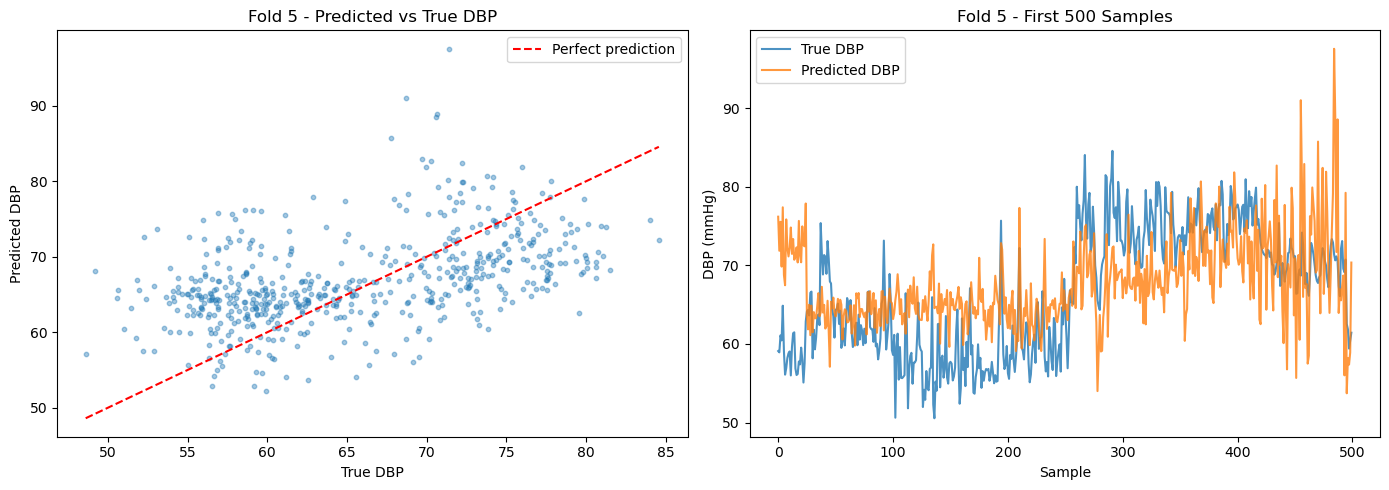


Final CV MAE's:
  SBP: 11.7828 ± 2.8385
  DBP: 7.4339 ± 1.1312


In [48]:
# Kernel init:
# Training: abp_t0 = abp[:, 0:1] / 100.0 — per-sample from true first ABP timestep
# Evaluation: abp_t0 = None → kernel uses GLOBAL_MEAN_T0 constant

batch_size = 32
num_epochs = 30

num_inputs = len(top_features_ALL)
num_hidden = 32
num_outputs = 10
num_timer_neurons = 10

beta_val = 0.9

cv_mae_sbp = 0.0
cv_mae_dbp = 0.0
cv_total_samples = 0

fold_maes_sbp = []
fold_maes_dbp = []

for fold in range(num_folds):
    print(f"\nFold {fold+1}/{num_folds}")

    net = Net(
        num_inputs,
        num_hidden,
        num_outputs,
        beta_val,
        num_steps,
        num_timer_neurons,
    )

    optimizer = optim.Adam(net.parameters(), lr=lr)

    test_data = load_data(fold)
    train_data = pd.concat([load_data(i) for i in range(num_folds) if i != fold])

    abp_test = torch.tensor(load_abp(fold), dtype=torch.float32)

    abp_train = torch.cat(
        [
            torch.tensor(load_abp(i), dtype=torch.float32)
            for i in range(num_folds)
            if i != fold
        ],
        dim=0,
    )

    lim_test = torch.tensor(load_limits(fold), dtype=torch.long)

    lim_train = torch.cat(
        [
            torch.tensor(load_limits(i), dtype=torch.long)
            for i in range(num_folds)
            if i != fold
        ],
        dim=0,
    )

    X_train = torch.tensor(
        train_data[top_features_ALL].values,
        dtype=torch.float32,
    )

    X_test = torch.tensor(
        test_data[top_features_ALL].values,
        dtype=torch.float32,
    )

    y_train = torch.tensor(
        train_data.iloc[:, 2:4].values,
        dtype=torch.float32,
    )

    y_test = torch.tensor(
        test_data.iloc[:, 2:4].values,
        dtype=torch.float32,
    )

    # min-max normalise
    mn = X_train.min(0).values
    mx = X_train.max(0).values

    X_train = (X_train - mn) / (mx - mn + eps)
    X_test = (X_test - mn) / (mx - mn + eps)

    train_loader = DataLoader(
        TensorDataset(X_train, y_train, abp_train, lim_train),
        batch_size=batch_size,
        shuffle=True,
    )

    # abp_test in test loader for plot_signal only — not used in prediction
    test_loader = DataLoader(
        TensorDataset(X_test, y_test, abp_test, lim_test),
        batch_size=batch_size,
        shuffle=False,
    )

    # Training
    for epoch in range(num_epochs):
        net.train()
        num_batches = total_loss = 0

        for x, y, abp, lim in train_loader:
            x = x.to(device)
            y, abp = y.to(device), abp.to(device)

            target = (abp / 100.0).permute(1, 0).unsqueeze(-1)

            abp_t0 = (abp[:, 0:1] / 100.0)

            optimizer.zero_grad()

            spk, init_val = net(x)
            sig = apply_exponential_kernel(spk, kernel_decay, net.spike_gain, init_val) * SCALING_FACTOR

            if SMOOTHING:
                sig = smooth(sig)

            loss = combined_loss(sig, target, lim, y[:, 0], y[:, 1], SP_MEAN_ALL)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)

            optimizer.step()

            with torch.no_grad():
                net.lif1.beta.clamp_(0.5, 0.99)
                net.lif2.beta.clamp_(0.5, 0.99)
                net.lif1.threshold.clamp_(0.1, 1.0)
                net.lif2.threshold.clamp_(0.1, 1.0)
                net.spike_gain.clamp_(-5.0, 5.0)

            total_loss += loss.item()
            num_batches += 1

        print(f"  Epoch {epoch+1:2d} | Loss: {total_loss/num_batches:.4f}")

    torch.save(net.state_dict(), f'checkpoint_fold_{fold+1}.pt')
    print(f'    Saved checkpoint: checkpoint_fold_{fold+1}.pt')
    
    net.eval()

    total_mae_sbp = total_mae_dbp = total_samples = 0

    true_sbp_list = []
    pred_sbp_list = []

    true_dbp_list = []
    pred_dbp_list = []

    first_batch = True

    with torch.no_grad():
        for x, y, abp, lim in test_loader:
            x = x.to(device)
            y = y.to(device)

            spk, init_val = net(x)
            sig = apply_exponential_kernel(spk, kernel_decay, net.spike_gain, init_val) * SCALING_FACTOR

            if SMOOTHING:
                sig = smooth(sig)

            pred_sbp, pred_dbp = extract_BP_limits(sig, lim)

            if first_batch:
                plot_signal(sig, spk, abp, lim, sample_idx=0)
                first_batch = False

            total_mae_sbp += torch.abs(pred_sbp - y[:, 0]).sum().item()
            total_mae_dbp += torch.abs(pred_dbp - y[:, 1]).sum().item()

            total_samples += y.shape[0]

            true_sbp_list.extend(y[:, 0].cpu().numpy())
            pred_sbp_list.extend(pred_sbp.cpu().numpy())

            true_dbp_list.extend(y[:, 1].cpu().numpy())
            pred_dbp_list.extend(pred_dbp.cpu().numpy())

    fold_mae_sbp = total_mae_sbp / total_samples
    fold_mae_dbp = total_mae_dbp / total_samples

    fold_maes_sbp.append(fold_mae_sbp)
    fold_maes_dbp.append(fold_mae_dbp)

    cv_mae_sbp += total_mae_sbp
    cv_mae_dbp += total_mae_dbp
    cv_total_samples += total_samples

    print(f"  → Fold MAE  SBP: {fold_mae_sbp:.4f}  DBP: {fold_mae_dbp:.4f}")

    plot_predictions(
        np.array(true_sbp_list),
        np.array(pred_sbp_list),
        "SBP",
        fold,
        500,
    )

    plot_predictions(
        np.array(true_dbp_list),
        np.array(pred_dbp_list),
        "DBP",
        fold,
        500,
    )

    print("\nFinal CV MAE's:")
    print(f"  SBP: {cv_mae_sbp/cv_total_samples:.4f} ± {np.std(fold_maes_sbp):.4f}")
    print(f"  DBP: {cv_mae_dbp/cv_total_samples:.4f} ± {np.std(fold_maes_dbp):.4f}")